# BIOT 6900 · Module 7 · Toy Knowledge Graph

### *Build the smallest possible graph by hand — zero setup, no database*

This is the **"I do"** demonstration from the Week 7 lecture. We build a tiny
Alzheimer's knowledge graph in pure Python, then do everything the lecture
promised, on a graph small enough to check by eye:

- store **nodes** (the things) and **typed edges with properties** (the relationships, with evidence on them),
- **walk the edges** to answer a question a table cannot,
- rank nodes by **centrality** (biomarker prioritization),
- find **communities** (patient / subtype grouping),
- and read every edge **skeptically**.

**Nothing to install tonight beyond `networkx`, `matplotlib`, `pandas`** — all
already in your `biot6900` environment. We use **NetworkX**, a pure-Python graph
library. It is *not* Neo4j, but for a graph this small it is perfect for *seeing*
the ideas. Every concept here (nodes, typed edges, properties, traversal,
centrality, community) transfers directly to Neo4j and Cypher next week.

> Run top to bottom with **Kernel → Restart & Run All**. Each cell builds on the one before it.


## 0 · Setup

One palette, reused everywhere, so a node's colour always means the same *kind*
of thing — the same colour code you saw on the lecture slides.

In [1]:
import networkx as nx
import pandas as pd
import matplotlib.pyplot as plt

print("networkx", nx.__version__)
print("pandas  ", pd.__version__)

# kind -> colour (matches the lecture's entity colours)
KIND_COLOR = {
    "gene":      "#D41B2C",   # Northeastern red  (the hero entity)
    "disease":   "#3E6F99",
    "phenotype": "#2FA3D6",
    "pathway":   "#00A58C",
    "drug":      "#9A5FC0",
    "variant":   "#FF854F",
}

networkx 3.7
pandas   3.0.5


## 1 · The smallest possible graph, by hand

A **property graph** has two building blocks:

- a **node** carries a `kind` (its label, like `:Gene`) plus any **properties** we want (an Ensembl id, say),
- an **edge** carries a `rel` (its type, like `ASSOCIATED_WITH`) plus **evidence that lives on the edge** (a p-value, a source).

We use a **directed** graph because biology has direction: a variant *occurs in*
a gene, not the reverse.

In [2]:
G = nx.DiGraph()

# NODES: name, kind, and (optionally) properties
G.add_node("APOE", kind="gene", ensembl="ENSG00000130203")
G.add_node("Alzheimer's", kind="disease")
G.add_node("Memory loss", kind="phenotype")
G.add_node("Lipid transport", kind="pathway")
G.add_node("rs429358", kind="variant")

# EDGES: the relationship type, with evidence ON the edge
G.add_edge("rs429358", "APOE",          rel="OCCURS_IN")
G.add_edge("APOE", "Alzheimer's",       rel="ASSOCIATED_WITH", pvalue=1e-20, source="GWAS")
G.add_edge("APOE", "Lipid transport",   rel="PARTICIPATES_IN")
G.add_edge("Alzheimer's", "Memory loss", rel="HAS_PHENOTYPE")

print(G)
print("nodes:", G.number_of_nodes(), " edges:", G.number_of_edges())

DiGraph with 5 nodes and 4 edges
nodes: 5  edges: 4


### Nodes and edges are *data*

Notice the p-value and source sitting **on the edge** — that is the property-graph
idea, and it is why an edge can be read as *evidence* rather than fact.

In [3]:
print("NODES  (the things)")
for n, a in G.nodes(data=True):
    props = {k: v for k, v in a.items() if k != "kind"}
    print(f"  {n:16s} kind={a['kind']:9s} {props}")

print("\nEDGES  (the relationships, with evidence on them)")
for u, v, a in G.edges(data=True):
    props = {k: v for k, v in a.items() if k != "rel"}
    print(f"  {u:12s} --{a['rel']:16s}--> {v:16s} {props}")

NODES  (the things)
  APOE             kind=gene      {'ensembl': 'ENSG00000130203'}
  Alzheimer's      kind=disease   {}
  Memory loss      kind=phenotype {}
  Lipid transport  kind=pathway   {}
  rs429358         kind=variant   {}

EDGES  (the relationships, with evidence on them)
  APOE         --ASSOCIATED_WITH --> Alzheimer's      {'pvalue': 1e-20, 'source': 'GWAS'}
  APOE         --PARTICIPATES_IN --> Lipid transport  {}
  Alzheimer's  --HAS_PHENOTYPE   --> Memory loss      {}
  rs429358     --OCCURS_IN       --> APOE             {}


## 2 · Draw it (colour = kind)

A small helper we reuse all notebook. If you can see the picture, the rest of
today is just reading it.

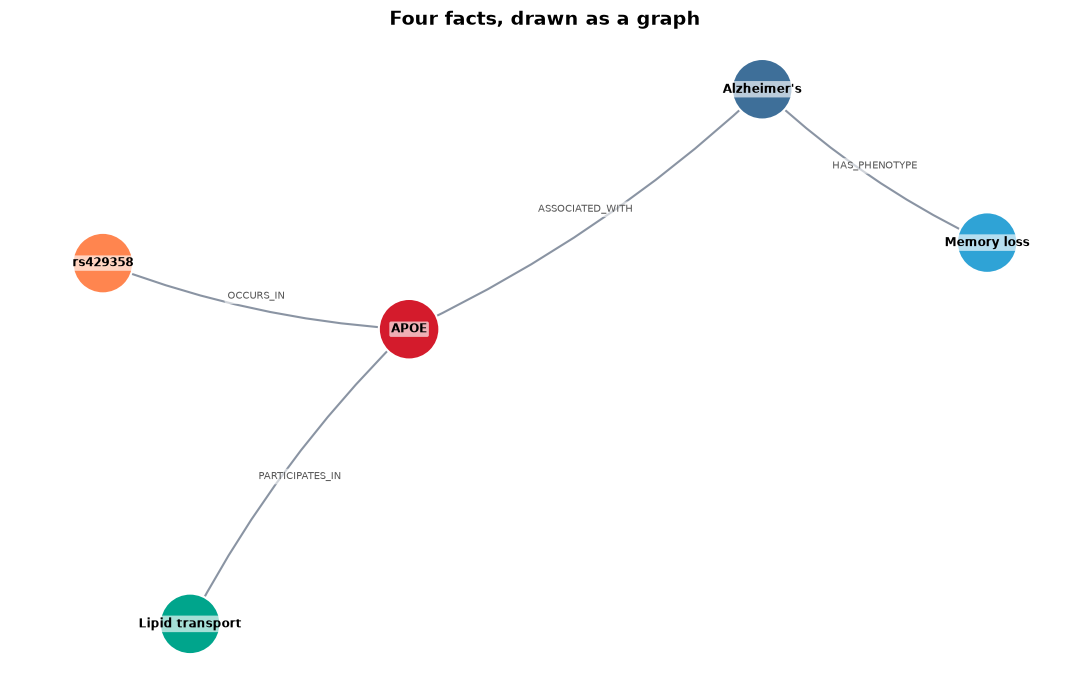

In [4]:
def draw_graph(G, title="", sizes=None, communities=None, seed=7):
    pos = nx.spring_layout(G, seed=seed, k=0.9)
    plt.figure(figsize=(11, 7))

    if communities is not None:                      # colour by community
        palette = ["#D41B2C", "#00A58C", "#3E6F99", "#9A5FC0", "#FF854F", "#2FA3D6"]
        node_color = [palette[communities[n] % len(palette)] for n in G.nodes()]
    else:                                            # colour by kind
        node_color = [KIND_COLOR[G.nodes[n]["kind"]] for n in G.nodes()]

    node_size = [1900] * G.number_of_nodes() if sizes is None else [sizes[n] for n in G.nodes()]

    nx.draw_networkx_edges(G, pos, arrows=True, arrowsize=15, edge_color="#8A94A3",
                           width=1.5, connectionstyle="arc3,rad=0.08")
    nx.draw_networkx_nodes(G, pos, node_color=node_color, node_size=node_size,
                           edgecolors="white", linewidths=1.5)
    nx.draw_networkx_labels(G, pos, font_size=8.5, font_color="black", font_weight="bold",
                            bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.65))
    elabels = {(u, v): d["rel"] for u, v, d in G.edges(data=True)}
    nx.draw_networkx_edge_labels(G, pos, edge_labels=elabels, font_size=7, font_color="#555",
                                 rotate=False,
                                 bbox=dict(boxstyle="round", fc="white", ec="none", alpha=0.6))
    plt.title(title, fontsize=14, fontweight="bold")
    plt.axis("off"); plt.tight_layout(); plt.show()

draw_graph(G, "Four facts, drawn as a graph")

## 3 · The identifier problem, in miniature

A callback to Module 2, with higher stakes. The **same gene** can wear different
ids across sources. If they are not resolved to **one node**, an edge silently
never forms — and a query returns nothing.

In [5]:
# Pretend two sources describe the SAME gene under different ids.
H = nx.DiGraph()
H.add_node("APOE", kind="gene")                 # source 1 (symbol)
H.add_node("ENSG00000130203", kind="gene")      # source 2 (Ensembl) — same gene!
H.add_node("Alzheimer's", kind="disease")
H.add_node("rs429358", kind="variant")
H.add_edge("APOE", "Alzheimer's", rel="ASSOCIATED_WITH")    # source 1 knows this
H.add_edge("rs429358", "ENSG00000130203", rel="OCCURS_IN")  # source 2 knows this

print("variant -> disease connected BEFORE resolving ids:",
      nx.has_path(H, "rs429358", "Alzheimer's"))

# Resolve both ids to ONE node; now the path forms.
H = nx.contracted_nodes(H, "APOE", "ENSG00000130203", self_loops=False)
print("variant -> disease connected AFTER  resolving ids:",
      nx.has_path(H, "rs429358", "Alzheimer's"))

variant -> disease connected BEFORE resolving ids: False
variant -> disease connected AFTER  resolving ids: True


Resolving ids to one node is where most real knowledge-graph work lives.
We keep our toy clean by using one id per gene from here on.

## 4 · Grow it into a small Alzheimer's knowledge graph

Now we build from two plain lists — one of nodes, one of edges — so you can see
the pattern you will reuse on real data. We add more Alzheimer's genes, a few
pathways and phenotypes, a **second disease (Parkinson's) that shares symptoms**,
and three drugs.

> **Honesty note.** This is a small, hand-curated *illustrative* graph, not a
> validated knowledge base. One edge is deliberately weak — we use it in §8.

nodes: 18  edges: 19


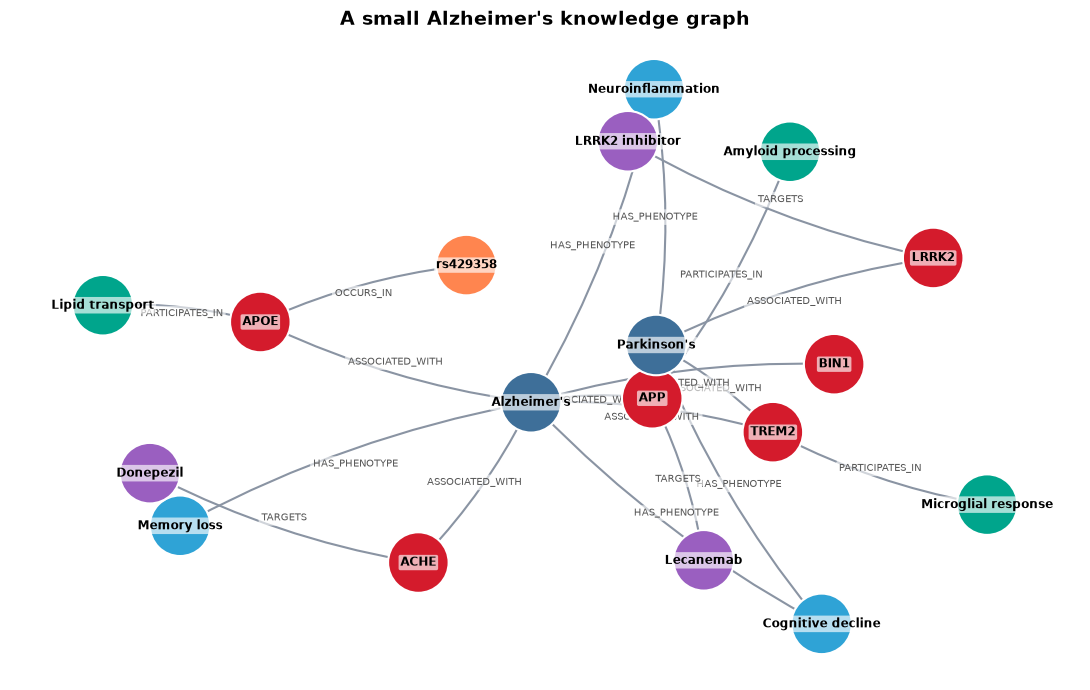

In [6]:
NODES = [
    ("APOE", "gene", {"ensembl": "ENSG00000130203"}),
    ("TREM2", "gene", {}), ("BIN1", "gene", {}), ("APP", "gene", {}),
    ("ACHE", "gene", {}), ("LRRK2", "gene", {}),
    ("Alzheimer's", "disease", {}), ("Parkinson's", "disease", {}),
    ("Memory loss", "phenotype", {}), ("Cognitive decline", "phenotype", {}),
    ("Neuroinflammation", "phenotype", {}),
    ("Lipid transport", "pathway", {}), ("Microglial response", "pathway", {}),
    ("Amyloid processing", "pathway", {}),
    ("rs429358", "variant", {}),
    ("Donepezil", "drug", {}), ("Lecanemab", "drug", {}), ("LRRK2 inhibitor", "drug", {}),
]

EDGES = [
    ("rs429358", "APOE", "OCCURS_IN", {}),
    ("APOE",  "Alzheimer's", "ASSOCIATED_WITH", {"pvalue": 1e-20, "source": "GWAS"}),
    ("TREM2", "Alzheimer's", "ASSOCIATED_WITH", {"pvalue": 1e-12, "source": "GWAS"}),
    ("BIN1",  "Alzheimer's", "ASSOCIATED_WITH", {"pvalue": 1e-9,  "source": "GWAS"}),
    ("APP",   "Alzheimer's", "ASSOCIATED_WITH", {"source": "curated"}),
    ("ACHE",  "Alzheimer's", "ASSOCIATED_WITH", {"source": "textbook"}),   # symptomatic target
    ("LRRK2", "Parkinson's", "ASSOCIATED_WITH", {"pvalue": 1e-15, "source": "GWAS"}),
    ("TREM2", "Parkinson's", "ASSOCIATED_WITH", {"pvalue": 3e-2, "source": "one mouse paper"}),  # WEAK
    ("APOE", "Lipid transport",     "PARTICIPATES_IN", {}),
    ("TREM2", "Microglial response", "PARTICIPATES_IN", {}),
    ("APP",  "Amyloid processing",   "PARTICIPATES_IN", {}),
    ("Alzheimer's", "Memory loss",       "HAS_PHENOTYPE", {}),
    ("Alzheimer's", "Cognitive decline", "HAS_PHENOTYPE", {}),
    ("Alzheimer's", "Neuroinflammation", "HAS_PHENOTYPE", {}),
    ("Parkinson's", "Cognitive decline", "HAS_PHENOTYPE", {}),   # shared with Alzheimer's
    ("Parkinson's", "Neuroinflammation", "HAS_PHENOTYPE", {}),   # shared with Alzheimer's
    ("Donepezil", "ACHE", "TARGETS", {}),
    ("Lecanemab", "APP",  "TARGETS", {}),
    ("LRRK2 inhibitor", "LRRK2", "TARGETS", {}),
]

G = nx.DiGraph()
for name, kind, props in NODES:
    G.add_node(name, kind=kind, **props)
for u, v, rel, props in EDGES:
    G.add_edge(u, v, rel=rel, **props)

print("nodes:", G.number_of_nodes(), " edges:", G.number_of_edges())
draw_graph(G, "A small Alzheimer's knowledge graph")

## 5 · Walk the edges — paths

In a table each hop was another join. In a graph it is one step along an edge.

In [7]:
print("APOE points to:               ", list(G.successors("APOE")))
print("Alzheimer's is pointed to by:  ", list(G.predecessors("Alzheimer's")))

deg = pd.Series(dict(G.degree())).sort_values(ascending=False)
print("\nMost connected nodes (degree):")
print(deg.head(6).to_string())

APOE points to:                ["Alzheimer's", 'Lipid transport']
Alzheimer's is pointed to by:   ['APOE', 'TREM2', 'BIN1', 'APP', 'ACHE']

Most connected nodes (degree):
Alzheimer's          8
Parkinson's          4
APOE                 3
APP                  3
TREM2                3
Neuroinflammation    2


### The opening question, 2 hops

> *Which drugs act on genes associated with Alzheimer's?*

`drug --TARGETS--> gene --ASSOCIATED_WITH--> disease`. One function, two hops.

In [8]:
def drugs_for_disease(G, disease):
    hits = []
    genes = [g for g in G.predecessors(disease)
             if G[g][disease].get("rel") == "ASSOCIATED_WITH"
             and G.nodes[g]["kind"] == "gene"]
    for g in genes:
        for d in G.predecessors(g):
            if G[d][g].get("rel") == "TARGETS":
                hits.append((d, g))
    return hits

print("Drugs acting on genes associated with Alzheimer's:")
for drug, gene in drugs_for_disease(G, "Alzheimer's"):
    print(f"  {drug}  --targets-->  {gene}  --associated_with-->  Alzheimer's")

Drugs acting on genes associated with Alzheimer's:
  Lecanemab  --targets-->  APP  --associated_with-->  Alzheimer's
  Donepezil  --targets-->  ACHE  --associated_with-->  Alzheimer's


### The full opening question, 5 hops

> *Which drugs act on genes associated with diseases that **share symptoms** with Alzheimer's?*

This is the question from the first slide — the one a table makes painful. In a
graph it is just a longer walk: Alzheimer's → its symptoms → other diseases with
those symptoms → their genes → drugs that target them. The answer is a
**drug-repurposing hypothesis**.

In [9]:
def repurposing_candidates(G, disease):
    symptoms = [p for p in G.successors(disease)
                if G[disease][p].get("rel") == "HAS_PHENOTYPE"]
    related = set()
    for p in symptoms:
        for d in G.predecessors(p):
            if G[d][p].get("rel") == "HAS_PHENOTYPE" and d != disease:
                related.add(d)
    out = []
    for rd in related:
        shared = [p for p in symptoms if G.has_edge(rd, p)]
        for drug, gene in drugs_for_disease(G, rd):
            out.append((drug, gene, rd, shared))
    return out

print("Repurposing hypotheses for Alzheimer's")
print("(drugs on genes of diseases that share a symptom):\n")
for drug, gene, rd, shared in repurposing_candidates(G, "Alzheimer's"):
    print(f"  {drug}  (targets {gene}, associated with {rd})")
    print(f"      shared symptom(s) with Alzheimer's: {', '.join(shared)}")

Repurposing hypotheses for Alzheimer's
(drugs on genes of diseases that share a symptom):

  LRRK2 inhibitor  (targets LRRK2, associated with Parkinson's)
      shared symptom(s) with Alzheimer's: Cognitive decline, Neuroinflammation


### The same question, in Cypher

Next week this exact walk becomes one legible pattern in Neo4j. Read it against
the five-way SQL join from the lecture:

```cypher
MATCH (d:Drug)-[:TARGETS]->(g:Gene)-[:ASSOCIATED_WITH]->(other:Disease)
      -[:HAS_PHENOTYPE]->(p:Phenotype)<-[:HAS_PHENOTYPE]-(ad:Disease)
WHERE ad.name = "Alzheimer's" AND other <> ad
RETURN d.name, g.name, other.name, p.name
```

One pattern, no `ON` clauses. That contrast is the whole point.

## 6 · Centrality = importance (biomarker prioritization)

Three flavours from the lecture: **degree** (raw connectedness),
**betweenness** (how often a node bridges shortest paths), and **PageRank**
(important if connected to important nodes). A hub gene is a candidate biomarker.

In [10]:
und = G.to_undirected()
pr  = nx.pagerank(G)                    # direction-aware importance
btw = nx.betweenness_centrality(und)    # bridges / bottlenecks
dc  = dict(G.degree())

rank = pd.DataFrame({"degree": dc, "betweenness": btw, "pagerank": pr})
rank["kind"] = [G.nodes[n]["kind"] for n in rank.index]

genes = rank[rank.kind == "gene"].sort_values("pagerank", ascending=False)
print("Genes ranked by PageRank (a hub gene is a candidate biomarker):\n")
print(genes.round(4).to_string())

Genes ranked by PageRank (a hub gene is a candidate biomarker):

       degree  betweenness  pagerank  kind
APOE        3       0.2279    0.0510  gene
APP         3       0.2279    0.0510  gene
ACHE        2       0.1176    0.0510  gene
LRRK2       2       0.1176    0.0510  gene
TREM2       3       0.1985    0.0275  gene
BIN1        1       0.0000    0.0275  gene


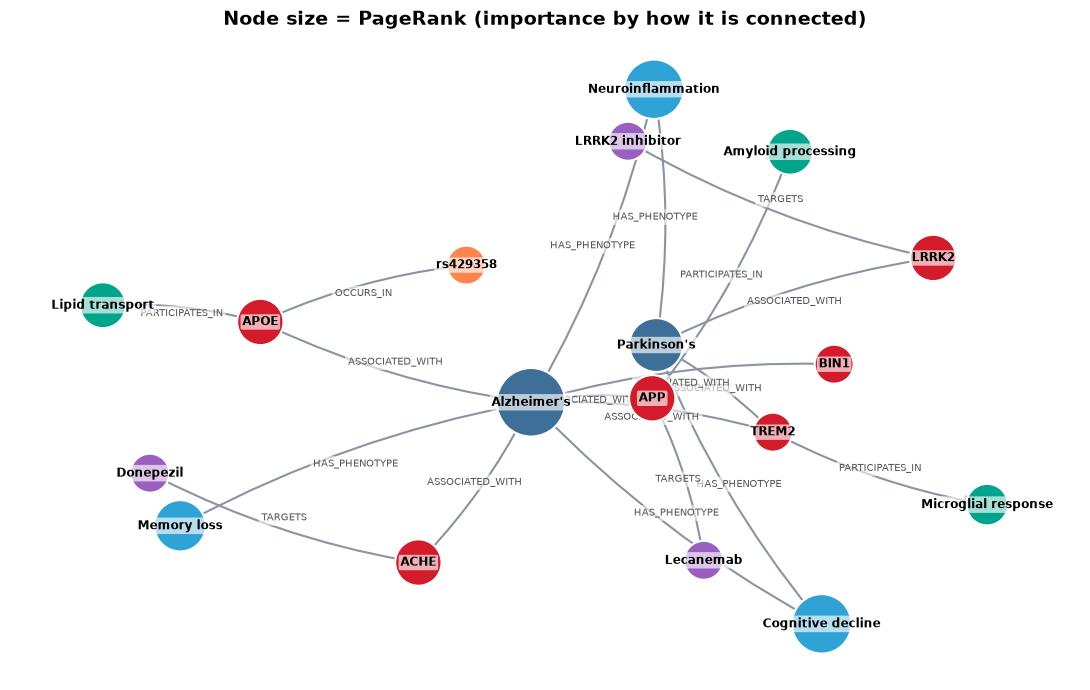

In [11]:
sizes = {n: 400 + 14000 * pr[n] for n in G.nodes()}
draw_graph(G, "Node size = PageRank (importance by how it is connected)", sizes=sizes)

## 7 · Community detection = natural groupings (stratification)

Dense within, sparse between. NetworkX ships Louvain-style modularity out of the
box — no extra install. A cluster can mark a disease subtype or a patient group.

Found 5 communities:
  community 0: ['Cognitive decline', 'LRRK2', 'LRRK2 inhibitor', 'Neuroinflammation', "Parkinson's"]
  community 1: ['ACHE', "Alzheimer's", 'BIN1', 'Donepezil', 'Memory loss']
  community 2: ['APOE', 'Lipid transport', 'rs429358']
  community 3: ['APP', 'Amyloid processing', 'Lecanemab']
  community 4: ['Microglial response', 'TREM2']


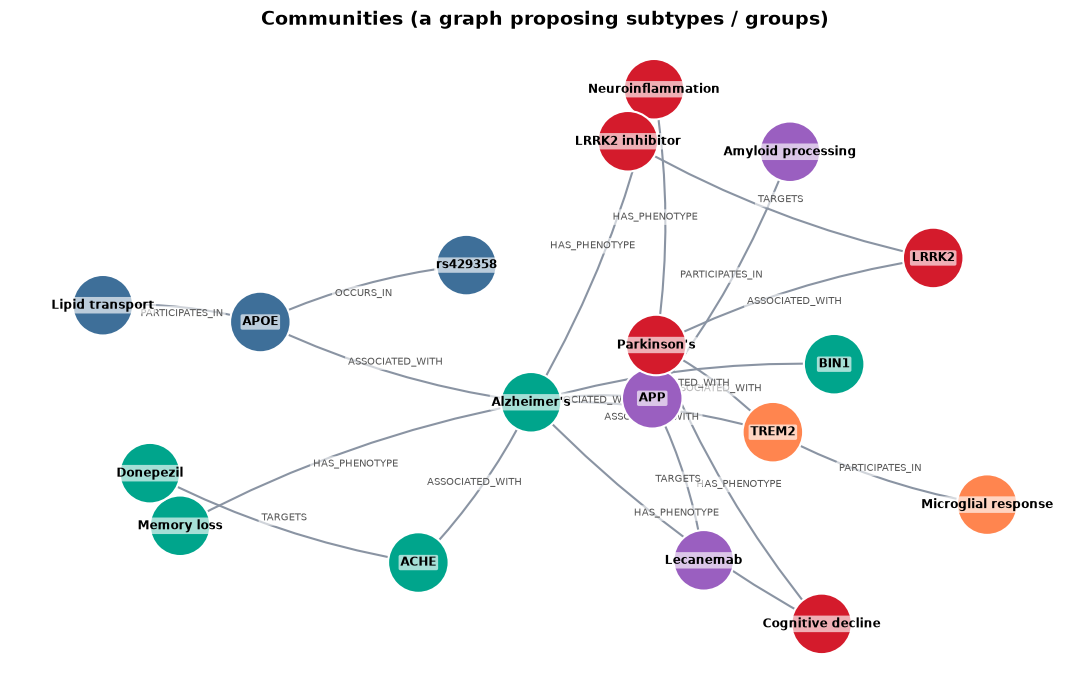

In [12]:
from networkx.algorithms.community import greedy_modularity_communities

comms = greedy_modularity_communities(G.to_undirected())
comm_of = {n: i for i, c in enumerate(comms) for n in c}

print(f"Found {len(comms)} communities:")
for i, c in enumerate(comms):
    print(f"  community {i}: {sorted(c)}")

draw_graph(G, "Communities (a graph proposing subtypes / groups)", communities=comm_of)

## 8 · The big caveat — an edge is evidence, not truth

A clean-looking graph can hide very uneven evidence. That is exactly why we keep
**source and confidence on the edge**: so we can filter on them. Watch the answer
change when we keep only well-supported associations.

In [13]:
# The deliberately weak edge:
for u, v, d in G.edges(data=True):
    if d.get("source") == "one mouse paper":
        props = {k: val for k, val in d.items() if k != "rel"}
        print(f"weak edge:  {u} --{d['rel']}--> {v}   {props}")

def strong(G):
    H = G.copy()
    drop = [(u, v) for u, v, d in H.edges(data=True)
            if d.get("rel") == "ASSOCIATED_WITH"
            and not (d.get("pvalue", 1.0) < 1e-5 or d.get("source") == "curated")]
    H.remove_edges_from(drop)
    return H

Gs = strong(G)
print("\nAlzheimer's genes, ALL edges   :", sorted(G.predecessors("Alzheimer's")))
print("Alzheimer's genes, STRONG only :", sorted(Gs.predecessors("Alzheimer's")))

print("\nDrugs for Alzheimer's, strong edges only:")
for drug, gene in drugs_for_disease(Gs, "Alzheimer's"):
    print(f"  {drug} -> {gene}")

weak edge:  TREM2 --ASSOCIATED_WITH--> Parkinson's   {'pvalue': 0.03, 'source': 'one mouse paper'}

Alzheimer's genes, ALL edges   : ['ACHE', 'APOE', 'APP', 'BIN1', 'TREM2']
Alzheimer's genes, STRONG only : ['APOE', 'APP', 'BIN1', 'TREM2']

Drugs for Alzheimer's, strong edges only:
  Lecanemab -> APP


Dropping the weakly-supported edges removes `ACHE` (a textbook symptomatic
target, not a disease-association), and with it the `Donepezil` hypothesis. Same
graph, different evidence bar, different answer. **Reading a knowledge graph well
means reading its edges skeptically.**

## 9 · What you built, and what's next

On a graph of ~18 nodes you did the whole lecture:

| Lecture idea | What you ran here |
|---|---|
| Property graph | nodes with a `kind`, edges with a `rel` + p-value / source |
| The identifier problem | §3, resolving two ids to one node |
| Paths beat joins | §5, the 2-hop and 5-hop walks |
| The opening question | §5, `repurposing_candidates(...)` → a drug-repurposing hypothesis |
| Centrality = biomarkers | §6, PageRank ranking of genes |
| Community = stratification | §7, modularity communities |
| An edge is evidence | §8, filter by confidence, watch the answer change |

**Next (Notebook B):** the same moves on *real* data — loading a slice of
Open Targets / Hetionet into **Neo4j** and querying it with **Cypher**, including
a natural-language **text-to-Cypher** helper.

**Then (graded assignment):** you build the graph for **your own Part I disease**,
starting from your `targets_ad.csv`, and answer the opening question for it.

---

### Try it yourself (optional, non-graded)

1. Add a gene `SORL1` associated with Alzheimer's (`pvalue=1e-8, source="GWAS"`), re-run §6, and see where it ranks.
2. Add a drug that targets it, then re-run the 2-hop query in §5.
3. Change the evidence bar in §8 from `1e-5` to `1e-10` and see which genes survive.


## 10 · Try it yourself — worked answers

We work on a copy, `G2`, so the graph above stays as it was.

### 1 · Add SORL1 and re-rank

In [14]:
G2 = G.copy()
G2.add_node("SORL1", kind="gene")
G2.add_edge("SORL1", "Alzheimer's", rel="ASSOCIATED_WITH", pvalue=1e-8, source="GWAS")

def gene_ranks(G):
    pr  = nx.pagerank(G)
    btw = nx.betweenness_centrality(G.to_undirected())
    r = pd.DataFrame({"degree": dict(G.degree()), "betweenness": btw, "pagerank": pr})
    r["kind"] = [G.nodes[n]["kind"] for n in r.index]
    return r[r.kind == "gene"].sort_values("pagerank", ascending=False)

print(gene_ranks(G2).round(4).to_string())

       degree  betweenness  pagerank  kind
APOE        3       0.2157    0.0476  gene
APP         3       0.2157    0.0476  gene
ACHE        2       0.1111    0.0476  gene
LRRK2       2       0.1111    0.0476  gene
TREM2       3       0.1895    0.0257  gene
BIN1        1       0.0000    0.0257  gene
SORL1       1       0.0000    0.0257  gene


SORL1 ties with BIN1 at the bottom. Its GWAS edge is as good as BIN1's, but in a
**directed** graph PageRank flows *along* the arrows: gene → disease. A gene only
gains PageRank from edges pointing **into** it, and here those are drug → gene
and variant → gene edges. So APOE, APP, ACHE and LRRK2 tie at the top because each
has one arrow coming in, and TREM2, with three disease/pathway links, ranks with
BIN1 because nothing points at it.

In this graph, directed PageRank measures "has a drug or variant pointing at it",
not "connected to the disease". For a hub-gene ranking the undirected version is
closer to what we want:

In [15]:
pr_und = nx.pagerank(G2.to_undirected())
cmp = pd.DataFrame({"pagerank_directed": nx.pagerank(G2), "pagerank_undirected": pr_und})
cmp = cmp[[G2.nodes[n]["kind"] == "gene" for n in cmp.index]]
print(cmp.sort_values("pagerank_undirected", ascending=False).round(4).to_string())

       pagerank_directed  pagerank_undirected
APOE              0.0476               0.0778
APP               0.0476               0.0778
TREM2             0.0257               0.0691
ACHE              0.0476               0.0527
LRRK2             0.0476               0.0523
BIN1              0.0257               0.0269
SORL1             0.0257               0.0269


Undirected, TREM2 (three links, one a bridge to Parkinson's) moves up beside APOE
and APP, and SORL1 and BIN1 stay at the bottom with one link each. Neither
version is "right"; the direction of the edges decides what the score means.

### 2 · Give SORL1 a drug, re-run the 2-hop query

There is no approved drug that targets SORL1, so the drug below is a
**placeholder**, the kind of node a real graph would only get from a trial or
compound database.

In [16]:
G2.add_node("SORL1 enhancer (hypothetical)", kind="drug")
G2.add_edge("SORL1 enhancer (hypothetical)", "SORL1", rel="TARGETS")

print("Drugs acting on genes associated with Alzheimer's:")
for drug, gene in drugs_for_disease(G2, "Alzheimer's"):
    print(f"  {drug}  --targets-->  {gene}")

print("\nSORL1 PageRank now:", round(nx.pagerank(G2)["SORL1"], 4))

Drugs acting on genes associated with Alzheimer's:
  Lecanemab  --targets-->  APP
  Donepezil  --targets-->  ACHE
  SORL1 enhancer (hypothetical)  --targets-->  SORL1

SORL1 PageRank now: 0.044


The new drug appears with no change to the query: the walk finds whatever is
connected. SORL1 also moves up in directed PageRank, purely because an arrow now
points into it, which confirms the point above.

### 3 · Raise the evidence bar from 1e-5 to 1e-10

In [17]:
def strong_at(G, bar):
    H = G.copy()
    drop = [(u, v) for u, v, d in H.edges(data=True)
            if d.get("rel") == "ASSOCIATED_WITH"
            and not (d.get("pvalue", 1.0) < bar or d.get("source") == "curated")]
    H.remove_edges_from(drop)
    return H, drop

for bar in [1e-5, 1e-10]:
    H, drop = strong_at(G2, bar)
    print(f"bar p < {bar:g}")
    print("  dropped edges :", [f"{u} -> {v}" for u, v in drop])
    print("  AD genes      :", sorted(H.predecessors("Alzheimer's")))
    print("  AD drugs      :", [f"{d} -> {g}" for d, g in drugs_for_disease(H, "Alzheimer's")])
    print("  repurposing   :", [f"{d} -> {g} ({rd})" for d, g, rd, _ in repurposing_candidates(H, "Alzheimer's")])

bar p < 1e-05
  dropped edges : ["TREM2 -> Parkinson's", "ACHE -> Alzheimer's"]
  AD genes      : ['APOE', 'APP', 'BIN1', 'SORL1', 'TREM2']
  AD drugs      : ['Lecanemab -> APP', 'SORL1 enhancer (hypothetical) -> SORL1']
  repurposing   : ["LRRK2 inhibitor -> LRRK2 (Parkinson's)"]
bar p < 1e-10
  dropped edges : ["TREM2 -> Parkinson's", "BIN1 -> Alzheimer's", "ACHE -> Alzheimer's", "SORL1 -> Alzheimer's"]
  AD genes      : ['APOE', 'APP', 'TREM2']
  AD drugs      : ['Lecanemab -> APP']
  repurposing   : ["LRRK2 inhibitor -> LRRK2 (Parkinson's)"]


At `1e-5` the filter drops two edges: ACHE → Alzheimer's (a textbook link with
no p-value, so it counts as p = 1) and the mouse-paper TREM2 → Parkinson's edge. Only the ACHE drop changes the answer (Donepezil disappears). The
mouse-paper edge §8 points at is removed too, but it never affected an Alzheimer's
answer, because no drug in the graph targets TREM2.

At `1e-10`, BIN1 (1e-9) and SORL1 (1e-8) also fall, and the SORL1 drug goes with
them. APOE (1e-20), TREM2 (1e-12) and APP (curated) survive. The LRRK2 repurposing
hypothesis survives every bar because LRRK2 → Parkinson's is 1e-15.

Note also that the filter treats `source == "curated"` as a free pass at any bar,
and a missing p-value as a fail. Both are choices, and both change the answer.